In [41]:
pip install phik

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik

path = '../data/raw'



In [43]:
sample_submission = pd.read_csv(f'{path}/sample_submission.csv')
train = pd.read_csv(f'{path}/train.csv')
test = pd.read_csv(f'{path}/test.csv')

In [44]:
train.head()

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,999,D-penicillamine,21532,M,N,N,N,N,2.3,316.0,3.35,172.0,1601.0,179.80,63.0,394.0,9.7,3.0,D
1,1,2574,Placebo,19237,F,N,N,N,N,0.9,364.0,3.54,63.0,1440.0,134.85,88.0,361.0,11.0,3.0,C
2,2,3428,Placebo,13727,F,N,Y,Y,Y,3.3,299.0,3.55,131.0,1029.0,119.35,50.0,199.0,11.7,4.0,D
3,3,2576,Placebo,18460,F,N,N,N,N,0.6,256.0,3.50,58.0,1653.0,71.30,96.0,269.0,10.7,3.0,C
4,4,788,Placebo,16658,F,N,Y,N,N,1.1,346.0,3.65,63.0,1181.0,125.55,96.0,298.0,10.6,4.0,C


In [45]:
LABEL = 'Status'
CAT_FEATS = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema", "Stage"]
NUM_FEATS = [x for x in train.columns if x not in CAT_FEATS and x != LABEL and x != 'id']

**profile report** 

In [46]:
# !pip install ydata-profiling

# from ydata_profiling import ProfileReport

In [47]:
profile_reports = False
if profile_reports:
  profile = ProfileReport(
                        train,
                        title="Prediction of Cirrhosis Outcomes",
                        explorative=True,
                        correlations={
                        "auto": {"calculate": False},
                        "phi_k": {"calculate": True}}
                        )
  profile

**Одномерный анализ**

**Категориальные признаки**

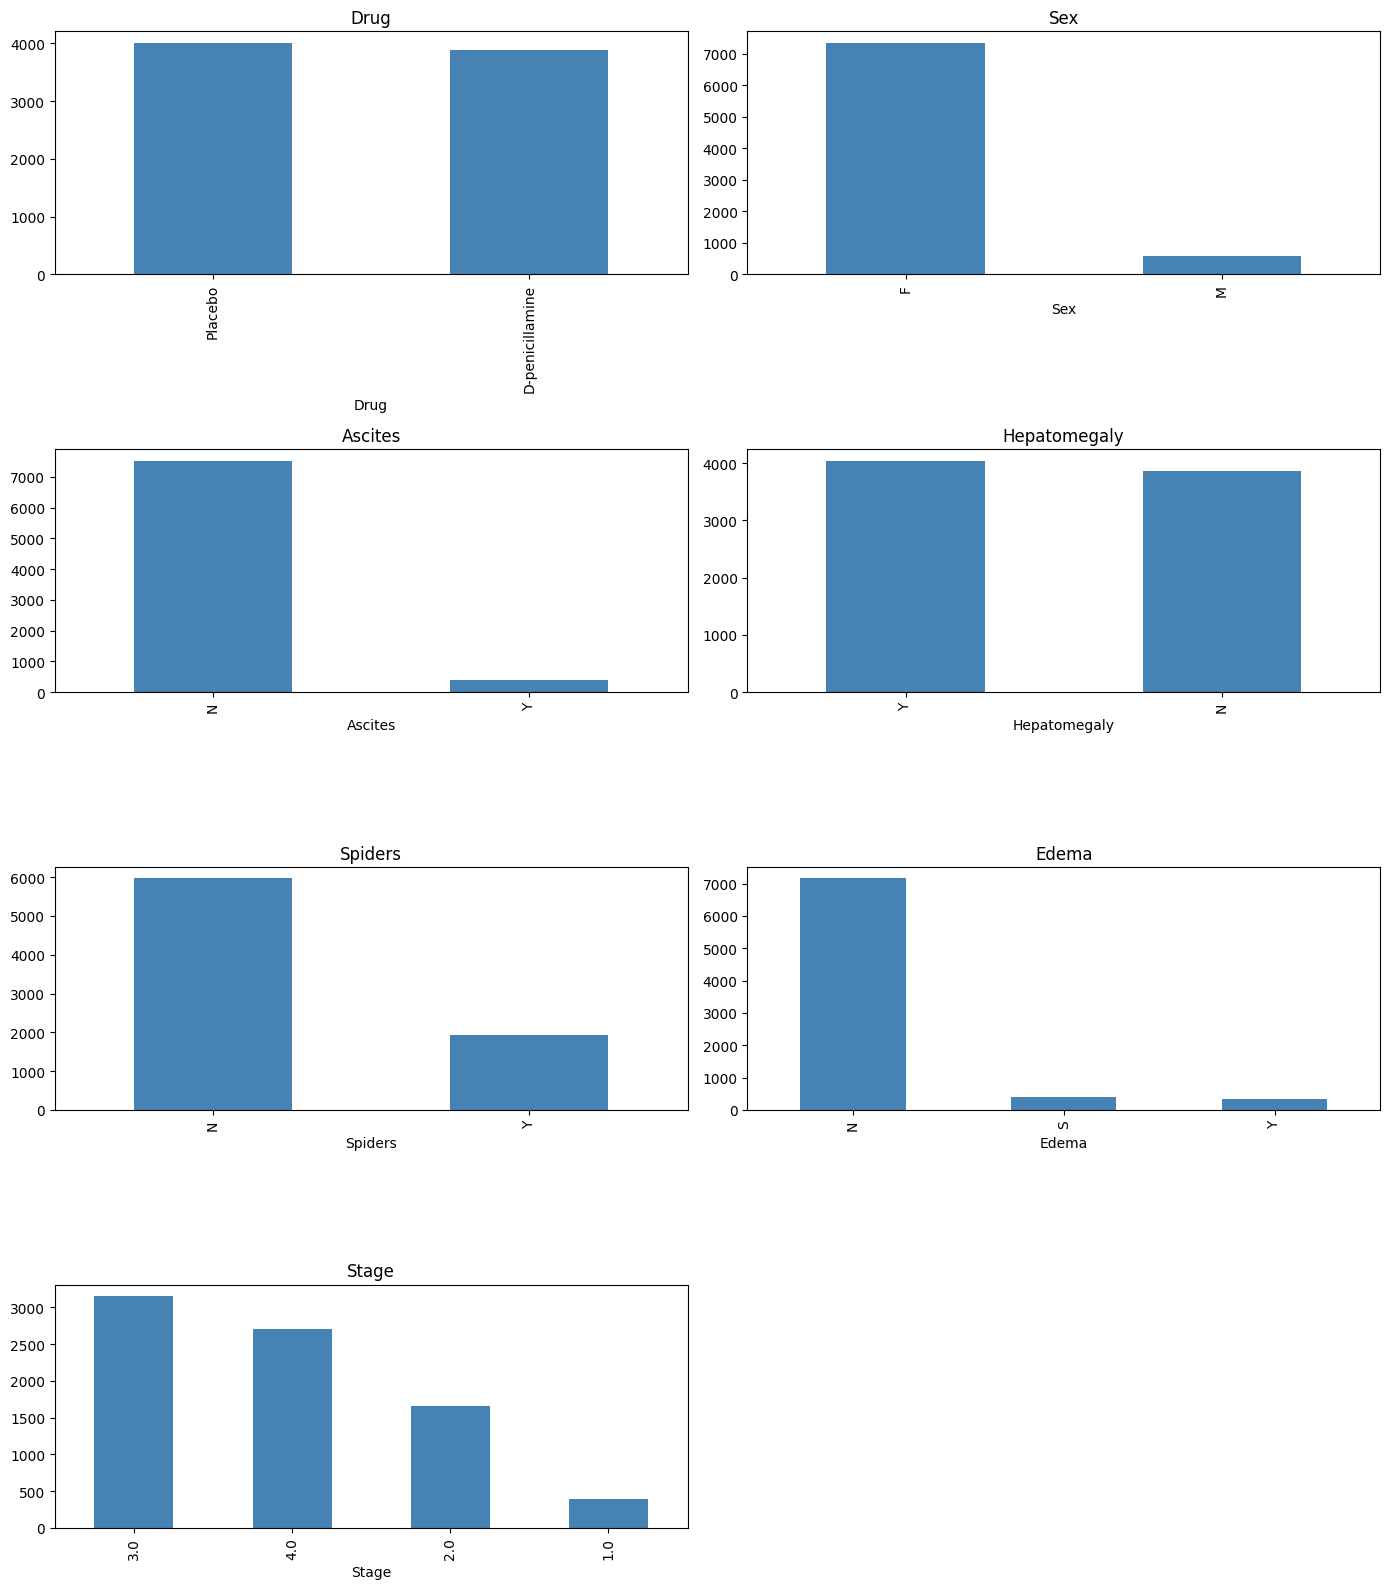

In [48]:
n = len(CAT_FEATS)
fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(14, 4 * ((n + 1) // 2)))
axes = axes.flatten()
for ax, col in zip(axes, CAT_FEATS):
    train[col].value_counts().plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col)
for ax in axes[n:]:
    ax.set_visible(False)
plt.tight_layout()
plt.savefig("eda_categorical.png", dpi=150)
plt.show()

- Drug сбалансирован почти идеально (50,7% placebo vs 49,3% D-penicillamine) - дизайн рандомизированного исследования соблюдён, само по себе лечение не должно быть сильным предиктором.
- Sex сильно перекошен: 92,8% женщин против 7,2% мужчин. Это типично для ПБХ, но означает, что модель будет слабо обобщаться на мужчин - стратифицировать выборку и не полагаться на Sex как на сильный признак.
- Ascites редкий (только 4,8% «Y») - признак поздней стадии, но именно поэтому потенциально сильно прогностический.
- Hepatomegaly распределён почти поровну (51,1% Y), Spiders - 24,5% Y. Умеренный дисбаланс, кодируются без проблем.
- Edema - три упорядоченных уровня (N 90,6% → S 5,0% → Y 4,4%); корректнее кодировать ординально, а не one-hot.
- Stage - дискретная шкала 1–4 с модой 3 (39,9%); по сути ординальная категория, а не числовой признак.

**Чисдовые признаки**

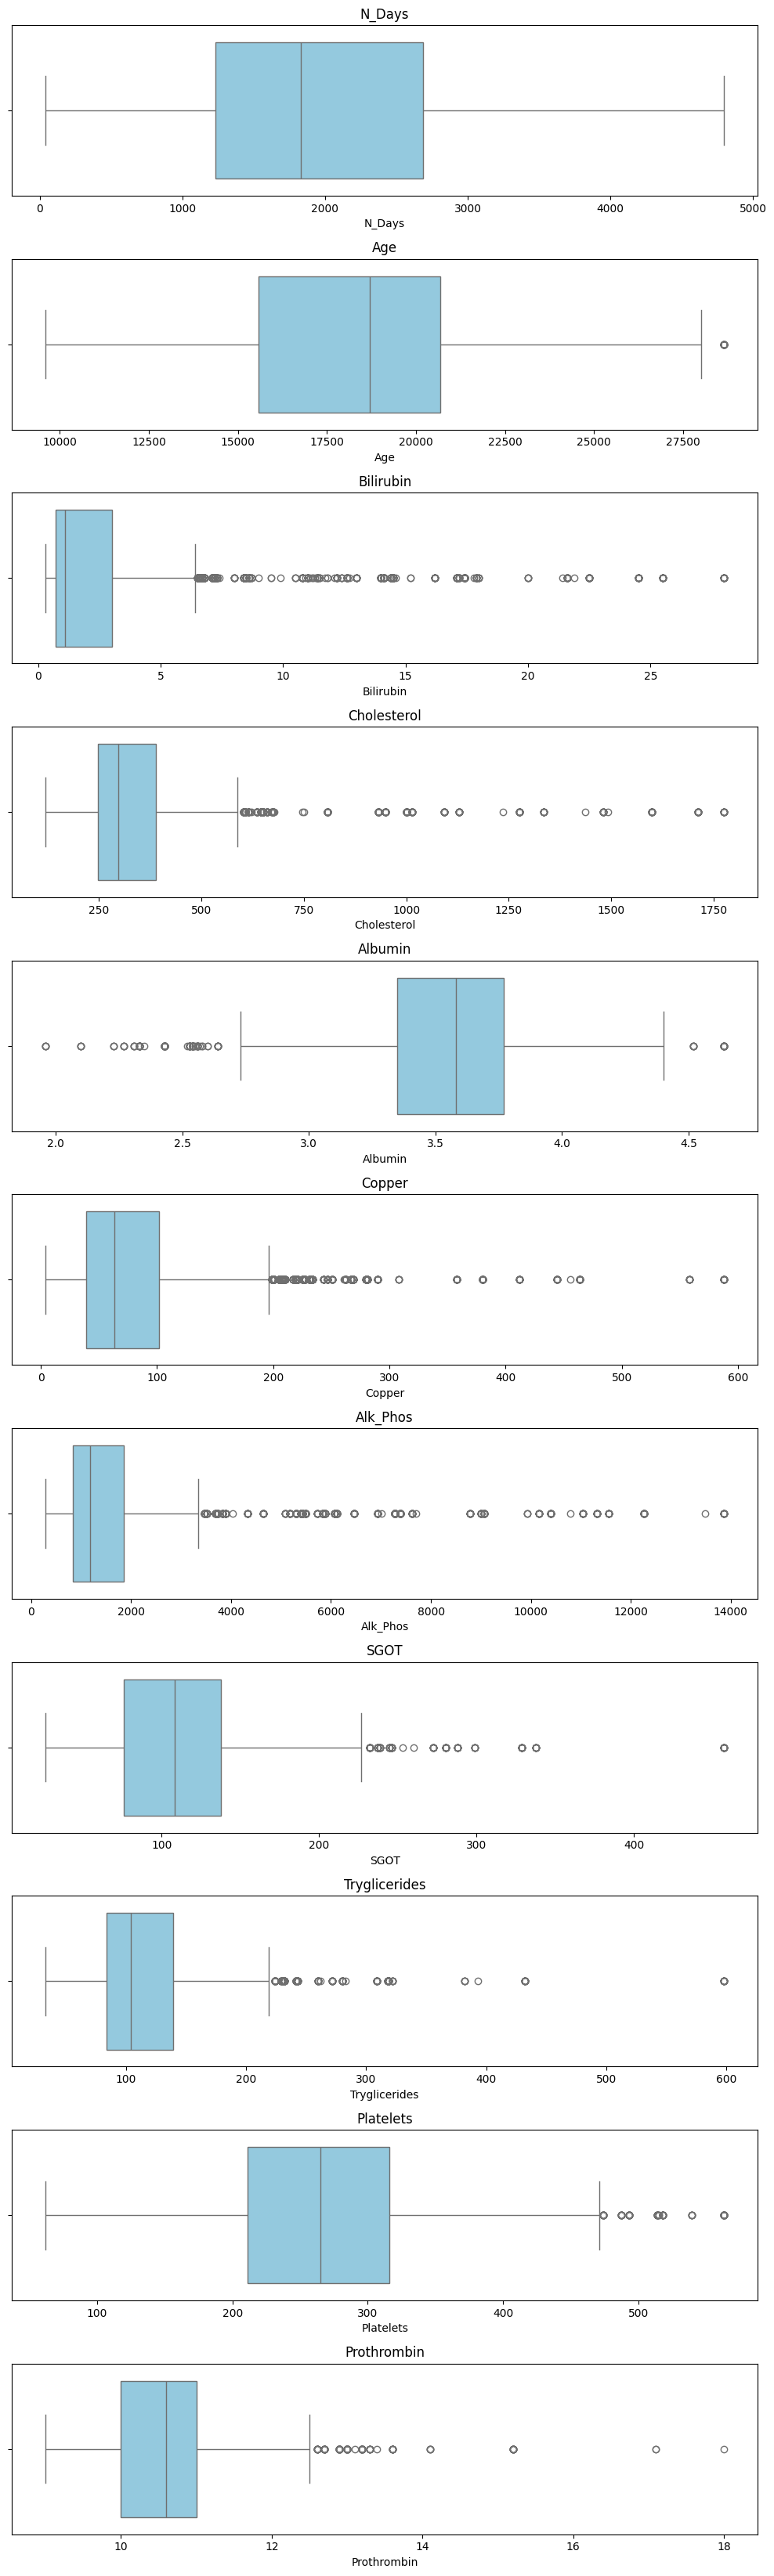

In [49]:
fig, axes = plt.subplots(len(NUM_FEATS), 1, figsize=(10, 3 * len(NUM_FEATS)))
for ax, col in zip(axes, NUM_FEATS):
    sns.boxplot(x=train[col], ax=ax, color="skyblue")
    ax.set_title(col)
plt.tight_layout()
plt.savefig("eda_boxplots.png", dpi=150)
plt.show()

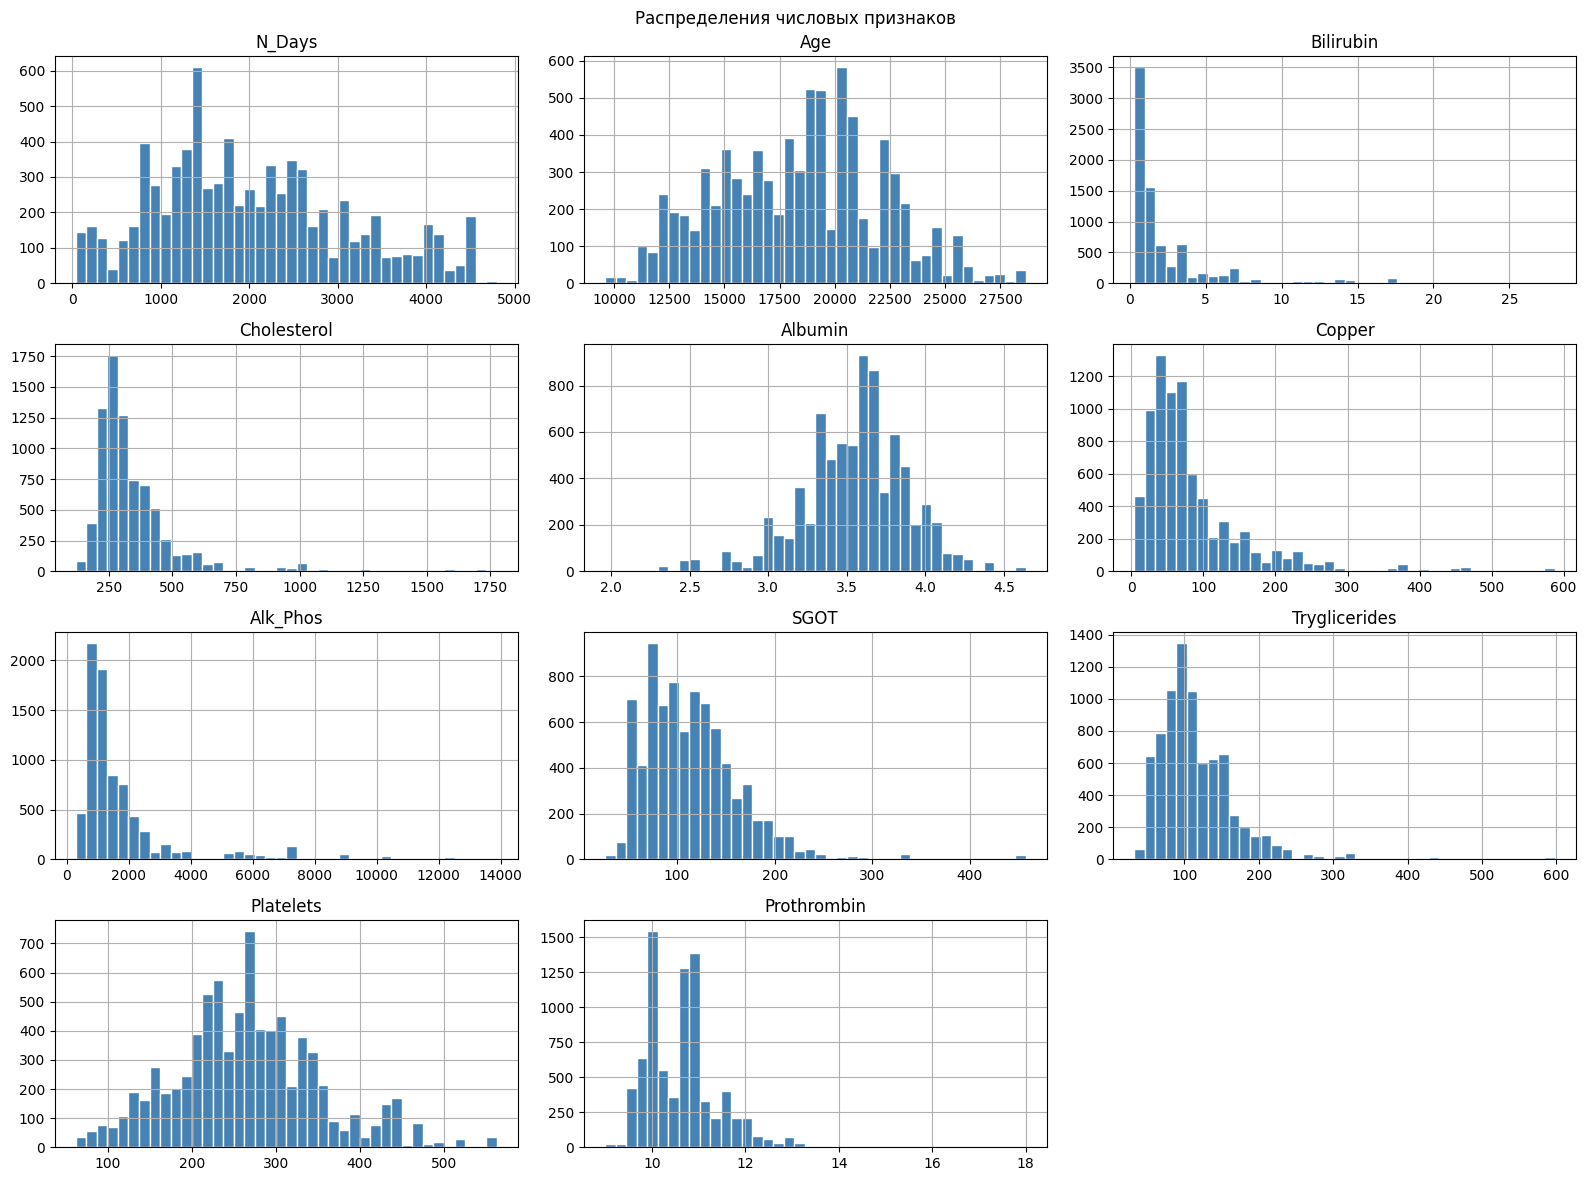

In [50]:
train[NUM_FEATS].hist(bins=40, figsize=(16, 12), color="steelblue", edgecolor="white")
plt.suptitle("Распределения числовых признаков")
plt.tight_layout()
plt.savefig("eda_histograms.png", dpi=150)
plt.show()


- Сильная правая асимметрия у Bilirubin (skew 3,34), Cholesterol (3,68), Alk_Phos (3,20), Copper (2,70), Tryglicerides (2,63): средние завышены относительно медиан, распределения - тяжёлые правые хвосты.
- Age (в записи - дни) распределён почти нормально: центр около 50 лет, диапазон 26–78.
- Albumin — единственный признак с заметной левой асимметрией (−0,56): клинически значим именно левый хвост (низкий альбумин - маркер плохого исхода), а не правый.
- Доля «выбросов» по правилу 1,5×IQR высока — до 10% у Alk_Phos (792 наблюдения) и Bilirubin (789). Но эти значения клинически правдоподобны (Alk_Phos до 13 862, Bilirubin до 28 — соответствует терминальным стадиям ПБХ).
- Platelets и Prothrombin смещены в «нормальный» диапазон с редкими тяжёлыми отклонениями (тромбоциты до 62 — маркер портальной гипертензии, протромбиновое время до 18 сек — коагулопатия): такие хвосты информативнее основной массы и не подлежат «очистке».

In [51]:
# для себя

# stats = pd.DataFrame({
#     "mean": train[NUM_FEATS].mean().round(2),
#     "median": train[NUM_FEATS].median().round(2),
#     "std": train[NUM_FEATS].std().round(2),
#     "min": train[NUM_FEATS].min(),
#     "max": train[NUM_FEATS].max(),
#     "skew": train[NUM_FEATS].skew().round(2),
#     "kurtosis": train[NUM_FEATS].kurtosis().round(2),
# })
# q1, q3 = train[NUM_FEATS].quantile(0.25), train[NUM_FEATS].quantile(0.75)
# iqr = q3 - q1
# outlier_share = ((train[NUM_FEATS] < q1 - 1.5 * iqr) | (train[NUM_FEATS] > q3 + 1.5 * iqr)).mean() * 100
# stats["outliers_%"] = outlier_share.round(1)
# print(stats.sort_values("skew", ascending=False))

**Многомерный анализ**

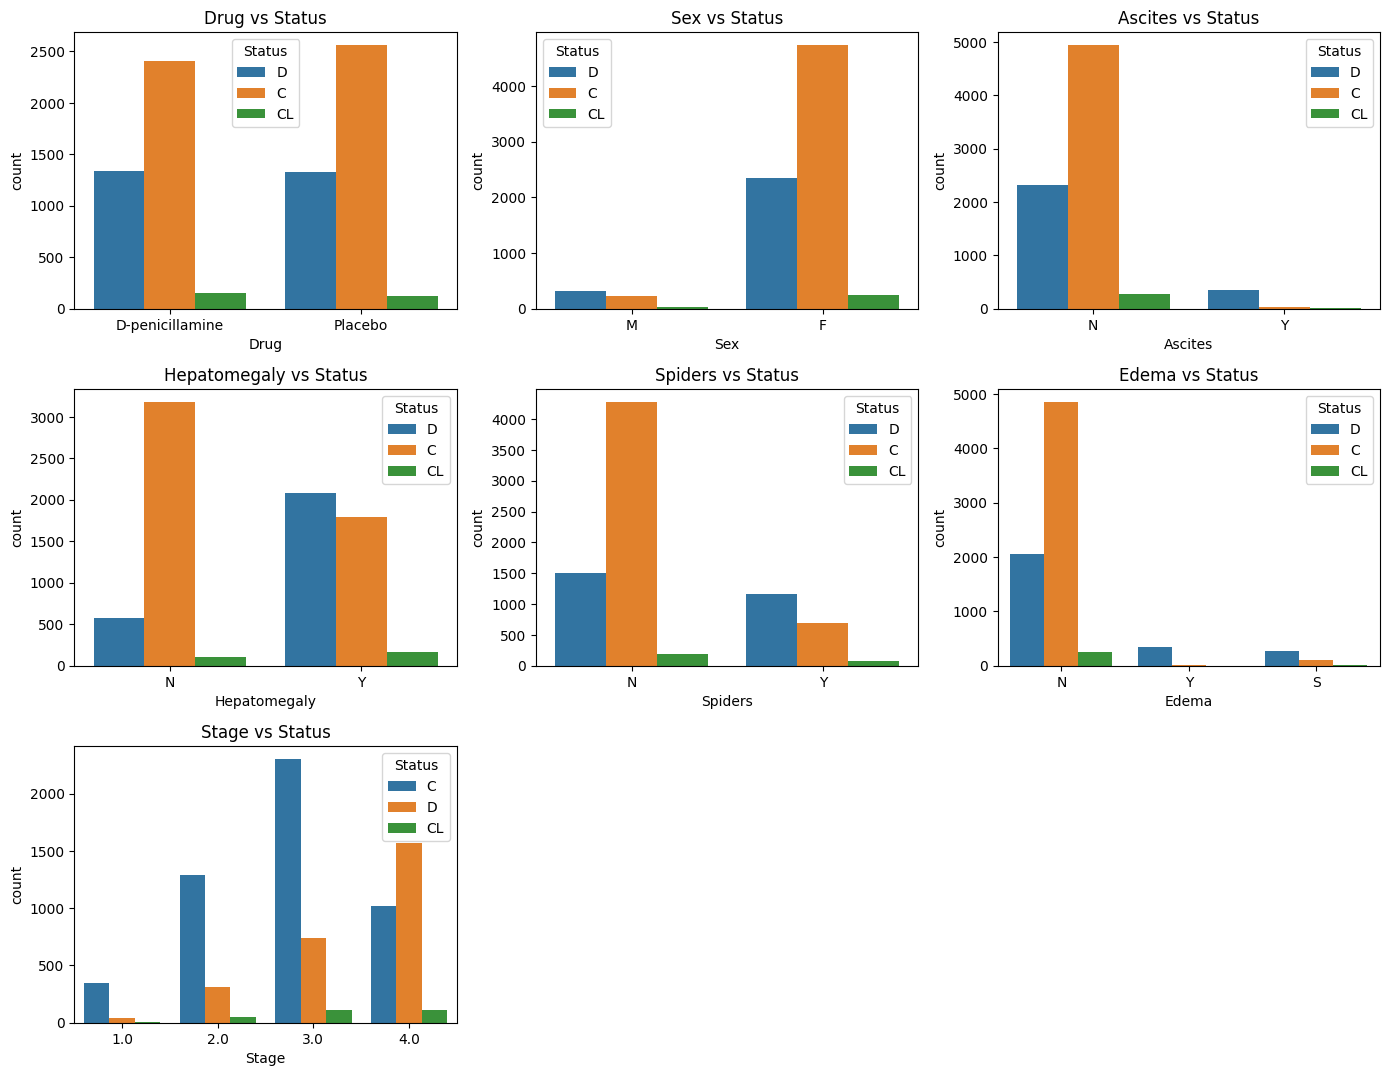

In [52]:
# Посмотрим на категориальные признаки
 
plt.figure(figsize=(14, len(CAT_FEATS) * 2))
for i, col in enumerate(CAT_FEATS):
    plt.subplot(len(CAT_FEATS) // 2 + 1, 3, i + 1)
    sns.countplot(x=col, hue=LABEL, data=train)
    plt.title(f"{col} vs {LABEL}")
    plt.tight_layout()

- У мужчин медианный билирубин 2,1 против 1,1 у женщин (p = 7×10⁻³¹) - то есть мужчины приходят к врачу с более запущенной болезнью. Sex - не самостоятельный фактор риска, а маркер более тяжёлого дебюта; при моделировании это проявится как реальный, но косвенный вклад.
- Drug: p = 0,053, на границе значимости, V = 0,03. Эффекта лечения нет - но не потому, что его «не видно», а потому, что его действительно нет (рандомизация чистая). Признак можно исключать.

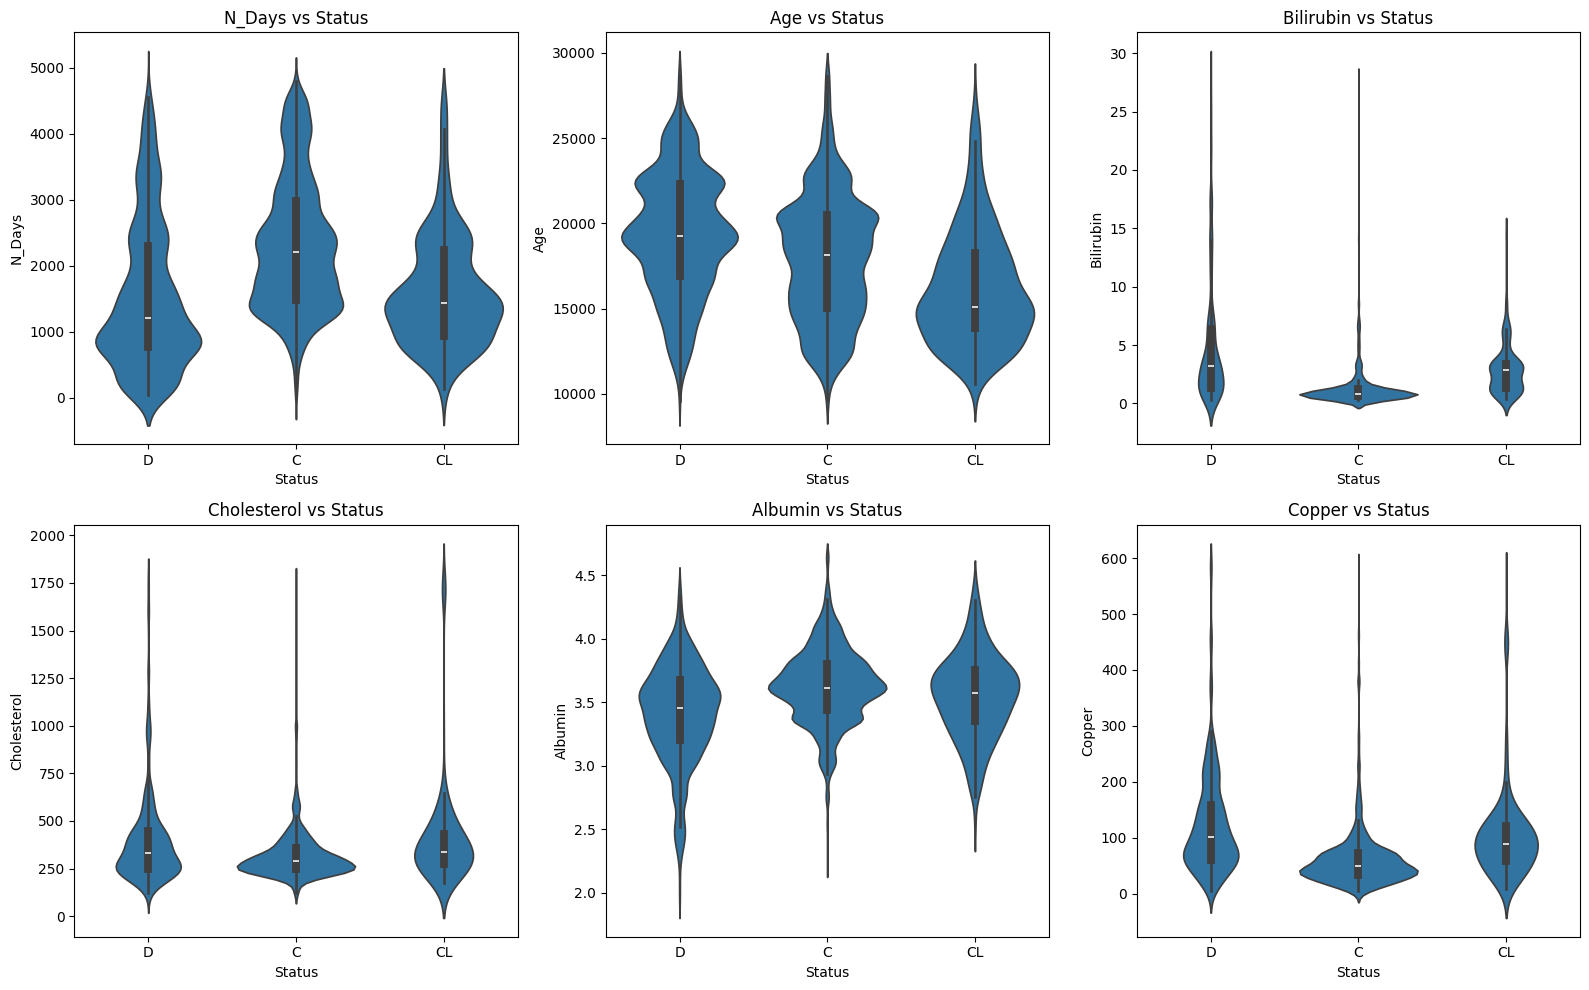

In [53]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for i, ax in enumerate(axes.flatten()):
    sns.violinplot(x=LABEL, y=NUM_FEATS[i], data=train, ax=ax)
    ax.set_title(f"{NUM_FEATS[i]} vs {LABEL}")
plt.tight_layout()
plt.show()

- Prothrombin имеет пороговый характер (~10,7 сек) - деревьям это на руку, линейным моделям лучше дать бинаризованный флаг «Prothrombin > 10,7».
- Билирубин важнее стадии: Stage 1 + высокий билирубин опаснее Stage 4 + низкий. Взаимодействие Stage × Bilirubin - кандидат на явную фичу в модели.
- Sex - косвенный маркер тяжести дебюта, эффект через билирубин; оставляем признак, но интерпретируем аккуратно.
- Drug не связан с исходом (p = 0,05, V = 0,03) - в модель не нужен.
- Симптомный блок комбинируется: Edema=Y + Ascites=Y - почти приговор (98,8%). Уже на EDA видно, что простое дерево правил уложится в приличное качество.

**Корреляционный анализ(Пирсон)**

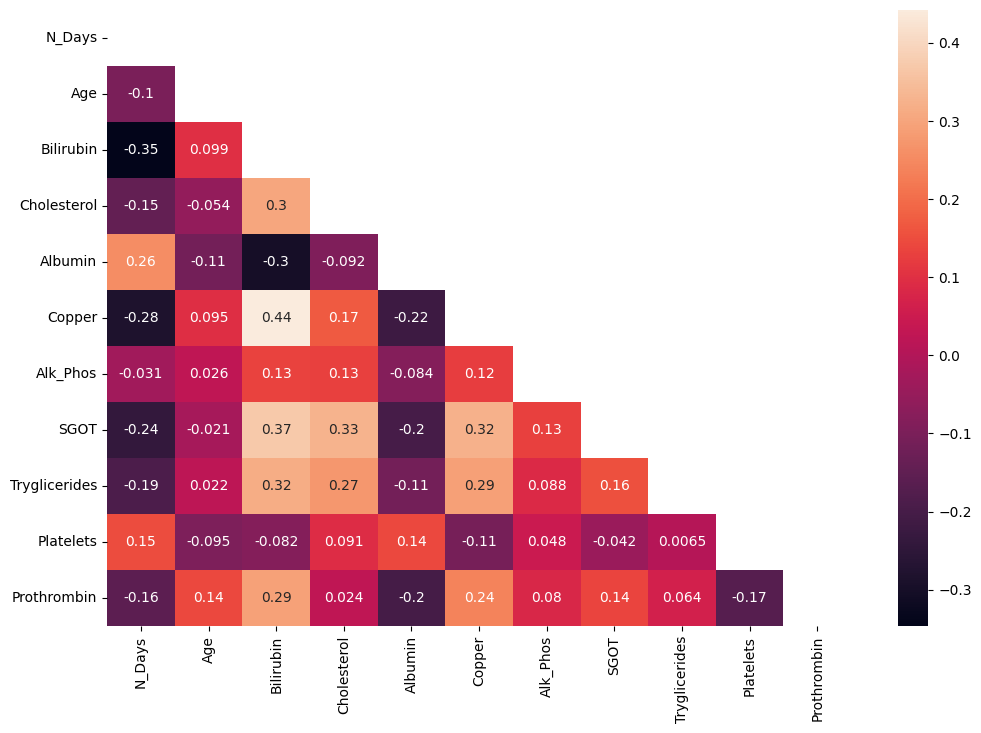

In [54]:
plt.figure(figsize=(12, 8))
mask = np.triu(np.ones_like(train[NUM_FEATS].corr(), dtype=bool))
sns.heatmap(train[NUM_FEATS].corr(), annot=True, mask=mask)
plt.show()

**Корреляционный анализ(phi_k)**

c:\Users\Данис\AppData\Local\Programs\Python\Python313\Lib\site-packages\phik\data_quality.py:59: UserWarning: The number of unique values of variable id is large: 7905. Are you sure this is not an interval variable? Analysis for pairs of variables including id can be slow.
  warnings.warn(


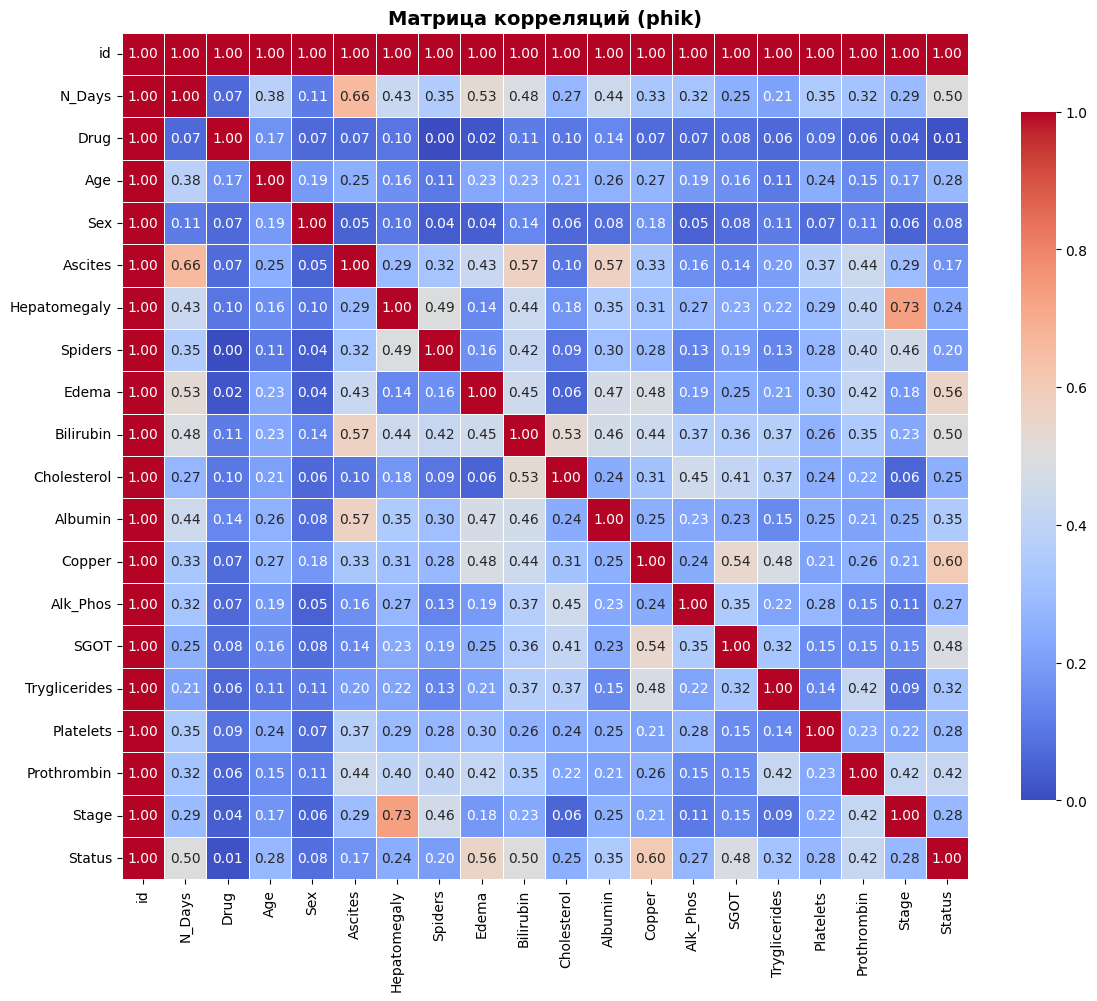

In [55]:
phik_matrix = train.phik_matrix(interval_cols=NUM_FEATS)


fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    phik_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)

ax.set_title("Матрица корреляций (phik)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

- Сильно коррелирующих признаков нет. Однако мы видим среднюю положительную корреляцию между медью и билирубином и среднюю отрицательную корреляцию между альбумином и билирубином.
- Для категориальных признаков имеющих бинарное распредление используем преобразование к 0 и 1 - Sex, Drug, Ascites, Spiders, Hepatomegaly
- Для Edema можно использовать, либо порядковое кодирование, но оно подойдет только для моделей деревьев или градиентного бустинга, так как линейные модели воспримут это как 1 > 2 в два раза, что не соотвествует реальной тяжести. Поэтому для линейных моделей предполагается использование One-Hot Encoding, т.е добавление столбцов Edema_N, Edema_S, Edema_Y.
- Stage уже кодирован, но как и Edema не отражает реальную тяжесть. Предположительно в зависимости от выбранной модели, так же использовать OHE или оставить как есть